# 02 · Where do delays concentrate?

Explore orders whose outcomes were available before validation began. The figures compare calendar periods and checkout characteristics at order grain. Changes across months or groups are descriptive associations. Model comparisons in notebook 03 use later orders.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data/checkout_features.json").is_file())
TABLES = ROOT / "results/tables"
FIGURES = ROOT / "results/figures"
orders = pd.read_parquet(ROOT / "data/processed/orders.parquet")
val_start = orders.loc[orders.split.eq("validation"), "purchased_at"].min().normalize()
train = orders.loc[orders.split.eq("train") & orders.label_observed_at.lt(val_start)].copy()
assert train.purchased_at.max() < val_start and train.label_observed_at.max() < val_start
base_rate = train.late.mean()
print(f"{len(train):,} training orders with known outcomes; {train.late.sum():,} late ({base_rate:.2%}).")
print(f"{(orders.split.eq('train')).sum() - len(train):,} training-window outcomes were still unavailable at the cutoff.")

64,401 training orders with known outcomes; 4,378 late (6.80%).
2,978 training-window outcomes were still unavailable at the cutoff.


## Inspect coverage before filling missing values

Distance requires a valid postal-prefix match for every seller involved. Physical totals require dimensions or weights for every item. The trained preprocessing pipeline in notebook 03 learns imputation values separately within each fit.

In [2]:
schema = json.loads((ROOT / "data/checkout_features.json").read_text())
features = sum(schema.values(), [])
profile = pd.DataFrame({
    "missing_orders": train[features].isna().sum(),
    "missing_fraction": train[features].isna().mean(),
    "distinct_observed": train[features].nunique(),
}).sort_values(["missing_orders", "distinct_observed"], ascending=False)
display(profile.style.format({"missing_fraction": "{:.2%}"}))
profile.to_csv(TABLES / "training_feature_coverage.csv", index_label="feature")

,missing_orders,missing_fraction,distinct_observed
primary_category,1174,1.82%,72
distance_km,327,0.51%,60783
volume_l,16,0.02%,5103
weight_kg,16,0.02%,2483
freight_brl,0,0.00%,6159
merchandise_brl,0,0.00%,5783
max_item_price_brl,0,0.00%,4354
purchase_hour_cos,0,0.00%,1296
purchase_hour_sin,0,0.00%,1286
promise_days,0,0.00%,95


## Time variation

Each point is the delay share among that month's eligible purchases. Bars give the denominator. The rate is shown for months with at least 100 observed outcomes. The final training month can underrepresent long deliveries because its labels must already be observable.

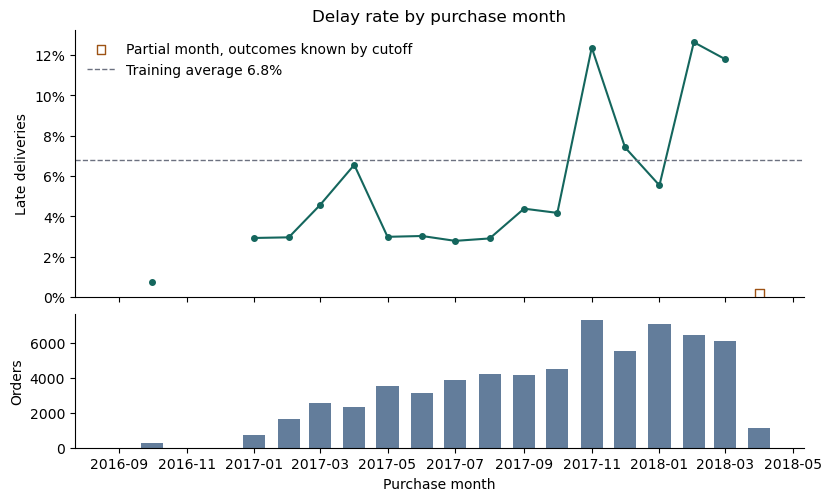

In [3]:
monthly = (train.set_index("purchased_at").late.resample("MS")
           .agg(["size", "sum", "mean"]).rename(columns={"size": "orders", "sum": "late_orders", "mean": "rate"}))
assert monthly.orders.sum() == len(train) and monthly.late_orders.sum() == train.late.sum()
monthly.to_csv(TABLES / "training_months.csv", index_label="month")
fig, (top, bottom) = plt.subplots(2, 1, figsize=(8.2, 4.9), sharex=True,
                                  gridspec_kw={"height_ratios": [2, 1]}, constrained_layout=True)
rate = monthly.rate.where(monthly.orders >= 100)
cutoff_month = monthly.index == val_start.to_period("M").start_time
top.plot(monthly.index, rate.mask(cutoff_month), color="#14665d", marker="o", ms=4)
top.scatter(monthly.index[cutoff_month], rate[cutoff_month], facecolors="none", edgecolors="#9d5214",
            marker="s", s=38, label="Partial month, outcomes known by cutoff", zorder=3)
top.axhline(base_rate, color="#6c7180", ls="--", lw=1, label=f"Training average {base_rate:.1%}")
top.legend(frameon=False, loc="upper left")
top.set(title="Delay rate by purchase month", ylabel="Late deliveries")
top.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
top.set_ylim(bottom=0)
bottom.bar(monthly.index, monthly.orders, width=20, color="#637d9b")
bottom.set(xlabel="Purchase month", ylabel="Orders")
for ax in (top, bottom):
    ax.spines[["right", "top"]].set_visible(False)
fig.savefig(FIGURES / "training_monthly_delays.png", dpi=140)
plt.show()

In the reference run, 901 of 7,285 orders in November 2017 were late (12.4%), compared with 187 of 4,478 in October (4.2%). April 2018 contains only orders with outcomes already observed by April 15. Its low rate cannot establish an improvement in fulfillment.

## Distance and the promised delivery window

Rows group the longest seller-to-buyer distance. Columns group the promised number of calendar days. Every displayed rate is paired with the number of eligible training orders. Cells below 50 orders are left blank to avoid overinterpreting sparse combinations.

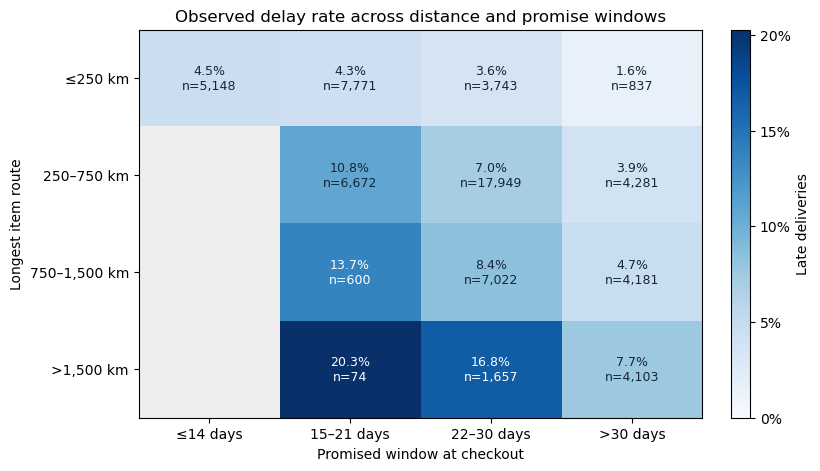

Orders without a complete route distance excluded from the grid: 327.


In [4]:
distance = pd.cut(train.distance_km, [-np.inf, 250, 750, 1500, np.inf],
                  labels=["≤250 km", "250–750 km", "750–1,500 km", ">1,500 km"])
promise = pd.cut(train.promise_days, [-np.inf, 14, 21, 30, np.inf],
                 labels=["≤14 days", "15–21 days", "22–30 days", ">30 days"])
pairs = (train.groupby([distance.rename("distance"), promise.rename("promise")], observed=False)
         .late.agg(orders="size", late_orders="sum", rate="mean"))
assert pairs.orders.sum() == train.distance_km.notna().sum()
pairs.to_csv(TABLES / "training_distance_by_promise.csv")
rates = pairs.rate.unstack()
counts = pairs.orders.unstack()
rates = rates.where(counts >= 50)
fig, ax = plt.subplots(figsize=(8.1, 4.6), constrained_layout=True)
cmap = plt.get_cmap("Blues").copy()
cmap.set_bad("#eeeeee")
image = ax.imshow(np.ma.masked_invalid(rates), cmap=cmap, aspect="auto", vmin=0)
mid = float(np.nanmax(rates)) * 0.55
for row, col in np.ndindex(rates.shape):
    rate, n = rates.iat[row, col], counts.iat[row, col]
    if pd.notna(rate):
        ax.text(col, row, f"{rate:.1%}\nn={n:,}", ha="center", va="center",
                color="white" if rate > mid else "#152538", fontsize=9)
ax.set_xticks(range(len(rates.columns)), rates.columns)
ax.set_yticks(range(len(rates.index)), rates.index)
ax.set(title="Observed delay rate across distance and promise windows",
       xlabel="Promised window at checkout", ylabel="Longest item route")
fig.colorbar(image, ax=ax, ticks=np.arange(0, np.nanmax(rates) + .001, .05),
             format=PercentFormatter(1, decimals=0), label="Late deliveries")
fig.savefig(FIGURES / "training_distance_by_promise.png", dpi=140)
plt.show()
print(f"Orders without a complete route distance excluded from the grid: {train.distance_km.isna().sum():,}.")

For a 22–30 day promise, the observed delay share increases from 3.6% for routes up to 250 km (3,743 orders) to 16.8% beyond 1,500 km (1,657 orders). Very few long routes were given promises of 14 days or less.

## Compare package and region groups

These are marginal rates. Differences in promise length, location and product mix can contribute to the same gap. Use the order counts to judge how much support each comparison has.

In [5]:
weight_band = pd.cut(train.weight_kg, [-np.inf, 1, 5, 15, np.inf],
                     labels=["≤1 kg", "1–5 kg", "5–15 kg", ">15 kg"])
volume_band = pd.cut(train.volume_l, [-np.inf, 5, 25, 75, np.inf],
                     labels=["≤5 L", "5–25 L", "25–75 L", ">75 L"])
route_type = train.interstate_item_share.map(lambda x:
    "Unknown" if pd.isna(x) else "Within state" if x == 0 else "All interstate" if x == 1 else "Mixed")
group_tables = []
for feature, group in {"package_weight": weight_band, "package_volume": volume_band, "state_crossing": route_type}.items():
    groups = pd.Series(group, index=train.index).astype("string").fillna("Unknown")
    counts = train.groupby(groups).late.agg(orders="size", late_orders="sum", delay_rate="mean")
    assert counts.orders.sum() == len(train)
    group_tables.append(counts.rename_axis("group").assign(feature=feature).reset_index())
segments = pd.concat(group_tables, ignore_index=True).set_index(["feature", "group"])
display(segments.style.format({"delay_rate": "{:.2%}"}))
segments.to_csv(TABLES / "training_package_and_route_groups.csv")